# EDA: Missing Values and Missingness Mechanism

Goal: check whether missing values are MCAR, MAR, or possibly MNAR, using the analytic sample (short-term acute + critical access hospitals).

Requires: `pip install statsmodels missingno scipy` in the `.venv`.

## 0. Setup

In [8]:
import re
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

conn = sqlite3.connect("../data/hospital_cost_reports.db")
df = pd.read_sql("SELECT * FROM cost_report_clean", conn)
a = df[df.ccn_facility_type.isin(["STH", "CAH"])].copy()

key = ["net_income", "total_income", "cash_on_hand_and_in_banks", "total_assets",
       "total_current_assets", "total_current_liabilities", "total_liabilities",
       "total_fixed_assets"]

print(df.shape)  # expect (48353, 118)
print(a.shape)   # expect (37204, 118)

(48353, 118)
(37204, 118)


## 1. Missing rates on the analytic sample

If rates differ a lot by facility type or year, MCAR is already in doubt.

In [9]:
overall = a[key].isna().mean().mul(100).round(1).rename("pct_missing")
overall.sort_values(ascending=False)

cash_on_hand_and_in_banks    3.7
total_fixed_assets           2.9
total_current_assets         2.5
total_current_liabilities    2.5
total_assets                 2.4
total_liabilities            2.4
net_income                   0.3
total_income                 0.3
Name: pct_missing, dtype: float64

In [10]:
a.groupby("ccn_facility_type")[key].apply(lambda g: g.isna().mean() * 100).round(1)

,net_income,total_income,cash_on_hand_and_in_banks,total_assets,total_current_assets,total_current_liabilities,total_liabilities,total_fixed_assets
ccn_facility_type,,,,,,,,
CAH,0.0,0.0,2.0,1.1,1.2,1.3,1.2,1.6
STH,0.4,0.4,4.4,2.9,3.0,3.0,2.9,3.4


In [11]:
a.groupby("type_of_control")[key].apply(lambda g: g.isna().mean() * 100).round(1)

,net_income,total_income,cash_on_hand_and_in_banks,total_assets,total_current_assets,total_current_liabilities,total_liabilities,total_fixed_assets
type_of_control,,,,,,,,
1,0.2,0.2,2.6,1.3,1.3,1.4,1.4,1.6
2,0.3,0.3,3.6,2.1,2.2,2.2,2.1,2.4
3,11.9,11.9,14.7,14.7,14.7,14.7,14.7,15.6
4,0.3,0.2,2.3,1.0,1.0,1.0,1.0,1.6
5,1.6,1.6,2.4,1.7,1.7,1.7,1.7,4.2
6,1.1,1.1,5.2,1.7,2.2,2.4,2.2,2.6
7,0.0,0.0,98.5,97.0,97.0,97.0,97.0,97.0
8,0.1,0.1,1.3,0.1,1.3,1.3,1.3,0.1
9,0.0,0.0,0.7,0.3,0.4,0.4,0.4,0.5


In [12]:
a.groupby("file_year")[key].apply(lambda g: g.isna().mean() * 100).round(1)

,net_income,total_income,cash_on_hand_and_in_banks,total_assets,total_current_assets,total_current_liabilities,total_liabilities,total_fixed_assets
file_year,,,,,,,,
2015,0.2,0.2,3.2,2.0,2.2,2.2,2.1,2.6
2016,0.3,0.2,3.2,2.1,2.2,2.2,2.2,2.6
2017,0.2,0.2,3.7,2.4,2.6,2.5,2.5,3.0
2018,0.3,0.3,3.7,2.3,2.4,2.3,2.3,2.7
2019,0.8,0.8,3.7,2.5,2.6,2.6,2.6,3.0
2020,0.3,0.3,4.0,2.6,2.7,2.7,2.7,3.1
2021,0.1,0.1,4.1,2.4,2.5,2.6,2.6,2.9
2022,0.2,0.2,4.3,2.5,2.7,2.7,2.7,3.2


## 2. Do fields go missing together?

High correlations among balance-sheet fields suggest whole worksheets are missing, not random cells.

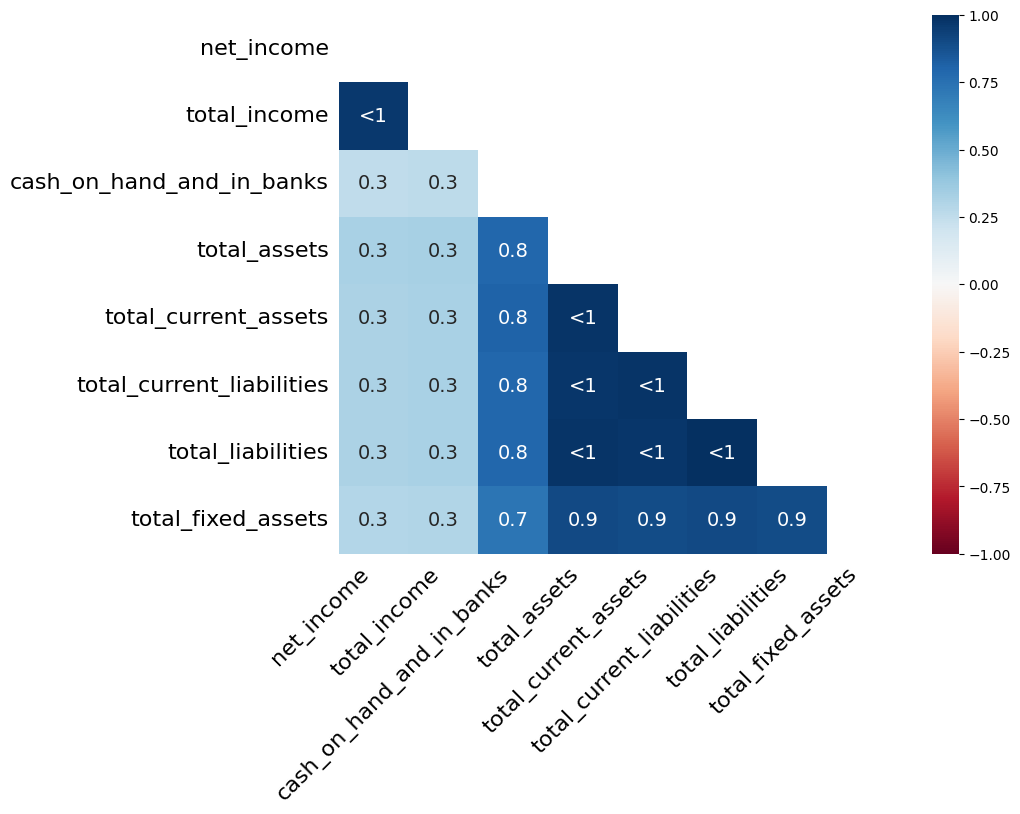

In [13]:
import missingno as msno

msno.heatmap(a[key], figsize=(9, 7))
plt.savefig("../reports/missingness_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

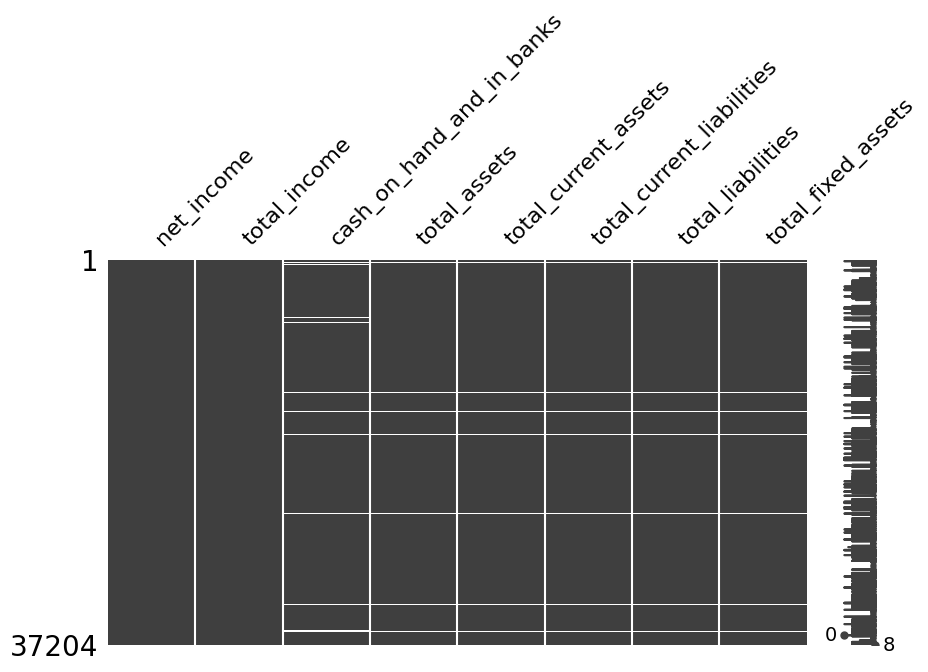

Rows missing all balance-sheet fields: 875
Rows missing any balance-sheet field:  935


In [14]:
msno.matrix(a.sort_values("file_year")[key], figsize=(10, 5))
plt.show()

bs = ["total_assets", "total_liabilities", "total_current_assets"]
print("Rows missing all balance-sheet fields:", a[bs].isna().all(axis=1).sum())
print("Rows missing any balance-sheet field: ", a[bs].isna().any(axis=1).sum())

## 3. Missingness indicator regression (main MAR test)

Significant predictors mean missingness depends on observed variables, which rejects MCAR and supports MAR conditional on these variables.

In [15]:
import statsmodels.formula.api as smf

ctrl_map = {1: "Nonprofit", 2: "Nonprofit",
            3: "For-profit", 4: "For-profit", 5: "For-profit", 6: "For-profit",
            7: "Federal",
            8: "Government", 9: "Government", 10: "Government", 11: "Government",
            12: "Government", 13: "Government"}
a["control_group"] = a.type_of_control.map(ctrl_map)
a["log_beds"] = np.log1p(a.number_of_beds)
print("Unmapped control codes:", a.control_group.isna().sum())

# Missing rate by ownership group
print(pd.crosstab(a.control_group, a.cash_on_hand_and_in_banks.isna(),
                  normalize="index").round(3))

# Fit without federal hospitals (near-total missingness = structural)
a_model = a[a.control_group != "Federal"].copy()
formula_rhs = ("C(ccn_facility_type) + C(control_group, Treatment('Nonprofit')) "
               "+ C(rural_versus_urban) + log_beds + C(file_year)")

for col in ["cash_on_hand_and_in_banks", "total_assets", "net_income"]:
    a_model[f"miss_{col}"] = a_model[col].isna().astype(int)
    try:
        m = smf.logit(f"miss_{col} ~ {formula_rhs}", data=a_model).fit(disp=0, maxiter=200)
        out = pd.DataFrame({"odds_ratio": np.exp(m.params), "p": m.pvalues}).round(3)
        print(f"\n===== Missing {col} =====  LLR p = {m.llr_pvalue:.2e}, "
              f"converged = {m.mle_retvals['converged']}")
        print(out)
    except Exception as e:
        print(f"{col}: model failed ({e})")

Unmapped control codes: 0
cash_on_hand_and_in_banks  False  True 
control_group                          
Federal                    0.015  0.985
For-profit                 0.973  0.027
Government                 0.985  0.015
Nonprofit                  0.966  0.034

===== Missing cash_on_hand_and_in_banks =====  LLR p = 4.82e-59, converged = True
                                                    odds_ratio      p
Intercept                                                0.010  0.000
C(ccn_facility_type)[T.STH]                              1.733  0.000
C(control_group, Treatment('Nonprofit'))[T.For-...       0.534  0.000
C(control_group, Treatment('Nonprofit'))[T.Gove...       0.617  0.000
C(rural_versus_urban)[T.U]                               2.006  0.000
C(file_year)[T.2016]                                     0.969  0.826
C(file_year)[T.2017]                                     1.240  0.116
C(file_year)[T.2018]                                     1.237  0.121
C(file_year)[T.2019] 

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 4. Little's MCAR test

Not run here. With ~37,000 rows it almost always rejects, and it assumes multivariate normality, which skewed financial data violates. If the report needs it, run `naniar::mcar_test()` in R, or the `pyampute` implementation in Python, and report it alongside section 3.

## 5. Probing MNAR with prior-year margins

If hospitals missing cash this year had worse margins last year, missingness is likely related to financial distress.

**Note:** margin here is `net_income / total_income`. Swap in the team's margin definition if different.

In [16]:
from scipy.stats import mannwhitneyu

a = a.sort_values(["provider_ccn", "file_year"])
a["margin"] = (a.net_income / (a.net_patient_revenue + a.total_other_income.fillna(0))
              ).replace([np.inf, -np.inf], np.nan)
print(a.margin.describe())
g = a.groupby("provider_ccn")
consecutive = g.file_year.diff().eq(1)
a["prior_margin"] = g.margin.shift(1).where(consecutive)

for col in ["cash_on_hand_and_in_banks", "total_assets"]:
    miss = a.loc[a[col].isna(), "prior_margin"].dropna()
    obs = a.loc[a[col].notna(), "prior_margin"].dropna()
    stat, p = mannwhitneyu(miss, obs)
    print(f"{col}: prior-year median margin, missing = {miss.median():.3f} (n={len(miss):,}), "
          f"observed = {obs.median():.3f} (n={len(obs):,}), Mann-Whitney p = {p:.2e}")

count    3.647100e+04
mean     8.777891e+02
std      1.676295e+05
min     -2.903148e+02
25%     -1.907091e-02
50%      4.244825e-02
75%      1.117128e-01
max      3.201284e+07
Name: margin, dtype: float64
cash_on_hand_and_in_banks: prior-year median margin, missing = 0.053 (n=624), observed = 0.046 (n=30,965), Mann-Whitney p = 3.52e-01
total_assets: prior-year median margin, missing = 0.038 (n=188), observed = 0.046 (n=31,401), Mann-Whitney p = 8.63e-01


In [17]:
print("Rows with |margin| > 1:", (a.margin.abs() > 1).sum())
print("Rows with net_patient_revenue <= 0:", (a.net_patient_revenue <= 0).sum())

a.loc[a.margin.abs() > 1,
      ["provider_ccn", "file_year", "ccn_facility_type", "net_income",
       "net_patient_revenue", "total_other_income", "margin"]
     ].sort_values("margin").head(15)

Rows with |margin| > 1: 185
Rows with net_patient_revenue <= 0: 32


,provider_ccn,file_year,ccn_facility_type,net_income,net_patient_revenue,total_other_income,margin
41434,450780,2021,STH,-2689476.0,1.0,9263.0,-290.314767
28820,390258,2019,STH,-375940211.0,-28917047.0,31359950.0,-153.890765
43446,100298,2022,STH,-140060324.0,1943633.0,NaN,-72.061096
37459,100298,2021,STH,-116638769.0,2572136.0,NaN,-45.347046
31464,100298,2020,STH,-122133962.0,3347602.0,NaN,-36.484015
25445,100298,2019,STH,-125911283.0,3989644.0,NaN,-31.559528
19396,100298,2018,STH,-119453490.0,4380566.0,NaN,-27.268963
41195,440235,2021,STH,-4335000.0,59608.0,101338.0,-26.934500
13326,100298,2017,STH,-118750559.0,4898536.0,NaN,-24.242051
1087,100298,2015,STH,-107971053.0,5220197.0,NaN,-20.683329


## 6. Attrition check (missing next-year outcome)

If hospitals that leave the panel had lower margins, dropping them biases the target.

In [18]:
a["present_next"] = g.file_year.shift(-1).eq(a.file_year + 1)
not_last = a[a.file_year < 2022]

print(not_last.present_next.value_counts())
print()
print(not_last.groupby("present_next").margin.describe().round(3))

left = not_last.loc[~not_last.present_next, "margin"].dropna()
stayed = not_last.loc[not_last.present_next, "margin"].dropna()
print(f"\nMann-Whitney p = {mannwhitneyu(left, stayed).pvalue:.2e}")

present_next
True     32228
False      398
Name: count, dtype: int64

                count   mean     std      min    25%    50%    75%      max
present_next                                                               
False           371.0 -0.861  16.007 -290.315 -0.341 -0.090  0.025   97.291
True          31589.0  0.042   2.019 -153.891 -0.013  0.046  0.115  311.090

Mann-Whitney p = 4.77e-53


In [19]:
# Exit rate by facility type
not_last.groupby("ccn_facility_type").present_next.apply(lambda s: (1 - s.mean()) * 100).round(2).rename("pct_exit_next_year")

ccn_facility_type
CAH    0.43
STH    1.54
Name: pct_exit_next_year, dtype: float64

## 7. Structural zeros in high-missing fields

If a field never contains 0, blanks are probably standing in for zero (not applicable).

In [20]:
high_missing = a.columns[a.isna().mean() > 0.5]
rows = []
for c in high_missing:
    rows.append({"column": c,
                 "pct_missing": round(100 * a[c].isna().mean(), 1),
                 "exact_zeros": int((a[c] == 0).sum()) if pd.api.types.is_numeric_dtype(a[c]) else None})
pd.DataFrame(rows).sort_values("pct_missing", ascending=False)

,column,pct_missing,exact_zeros
20,drg_amounts_other_than_outlier_payments,100.0,NaN
3,hospital_total_days_title_v_for_adults_peds,97.4,0.0
4,hospital_total_discharges_title_v_for_adults_peds,97.2,0.0
2,total_discharges_title_v,97.2,0.0
1,total_days_title_v,97.0,0.0
9,notes_receivable,94.5,0.0
19,unsecured_loans,94.1,0.0
5,wage_related_costs_rhc_fqhc,91.6,0.0
6,wage_related_costs_for_part_a_teaching_physicians,91.3,0.0
13,health_information_technology_designated_assets,88.9,0.0


## 8. Pipeline coercion check

The pipeline converts unparseable values to NaN. This checks whether some 'missing' values actually exist in the raw CMS file.

In [21]:
def clean_column_name(name):
    name = name.strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

raw = pd.read_csv("../data/raw/CostReport_2022_Final.csv", dtype=str, low_memory=False)
raw.columns = [clean_column_name(c) for c in raw.columns]

for c in key:
    if c not in raw.columns:
        print(f"{c}: not found in raw file")
        continue
    s = raw[c].dropna()
    bad = s[pd.to_numeric(s.str.replace(",", "", regex=False), errors="coerce").isna()]
    print(f"{c}: {len(bad)} values lost to parsing", list(bad.unique()[:5]))

net_income: 0 values lost to parsing []
total_income: 0 values lost to parsing []
cash_on_hand_and_in_banks: 0 values lost to parsing []
total_assets: 0 values lost to parsing []
total_current_assets: 0 values lost to parsing []
total_current_liabilities: 0 values lost to parsing []
total_liabilities: 0 values lost to parsing []
total_fixed_assets: 0 values lost to parsing []


## 9. Summary

In [22]:
print("Analytic sample:", f"{len(a):,} hospital-years, {a.provider_ccn.nunique():,} hospitals")
print("\nMissing % on key fields:")
print(overall.sort_values(ascending=False).to_string())
print("\nHigh-missing (>50%) columns:", len(high_missing))

Analytic sample: 37,204 hospital-years, 4,954 hospitals

Missing % on key fields:
cash_on_hand_and_in_banks    3.7
total_fixed_assets           2.9
total_current_assets         2.5
total_current_liabilities    2.5
total_assets                 2.4
total_liabilities            2.4
net_income                   0.3
total_income                 0.3

High-missing (>50%) columns: 26


In [23]:
print("Federal hospital-years:", (a.control_group == "Federal").sum())
print("Missing net_income rows:", a.net_income.isna().sum())
print("High-missing columns (>50%):", len(high_missing))

Federal hospital-years: 330
Missing net_income rows: 109
High-missing columns (>50%): 26
